In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

In [2]:
path = 'datasets/Mall_Customers.csv'
data = pd.read_csv(path)

In [3]:
data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [5]:
data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [6]:
data = data.drop('CustomerID' , axis=1)

In [7]:
data.head()

,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


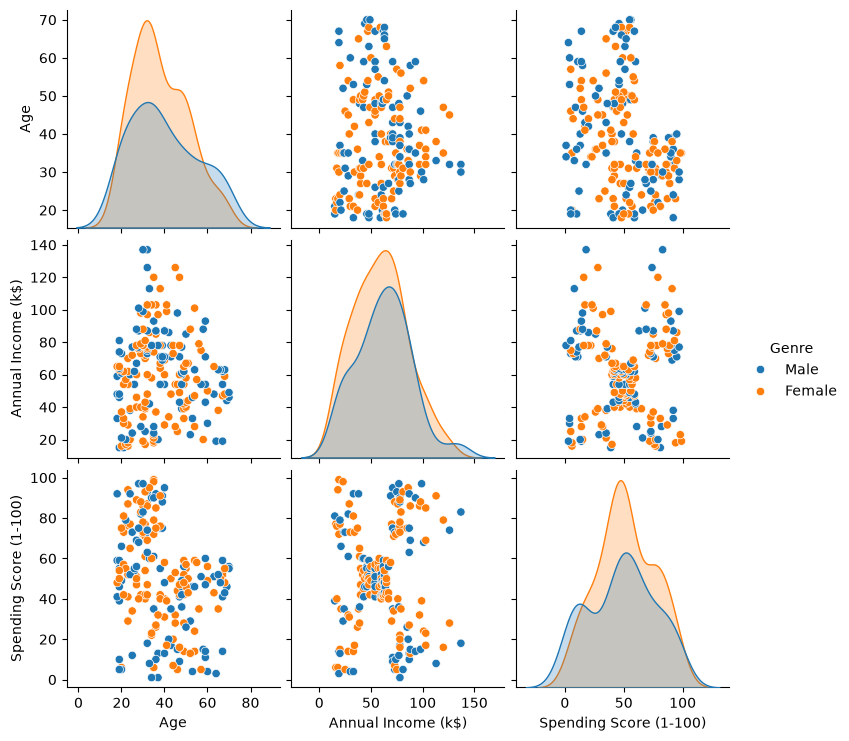

In [8]:
sns.pairplot(data , hue='Genre')

In [9]:
le = LabelEncoder()
data['Genre'] = le.fit_transform(data['Genre'])
data.head()

,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40


In [10]:
data['Genre'].value_counts()

Genre
0    112
1     88
Name: count, dtype: int64

In [11]:
data.columns

Index(['Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)'], dtype='str')

In [12]:
scaler = StandardScaler()
data[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']] = scaler.fit_transform(data[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']])

In [13]:
data.head()

,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,-1.424569,-1.738999,-0.434801
1,1,-1.281035,-1.738999,1.195704
2,0,-1.352802,-1.700830,-1.715913
3,0,-1.137502,-1.700830,1.040418
4,0,-0.563369,-1.662660,-0.395980


<Axes: xlabel='Annual Income (k$)'>

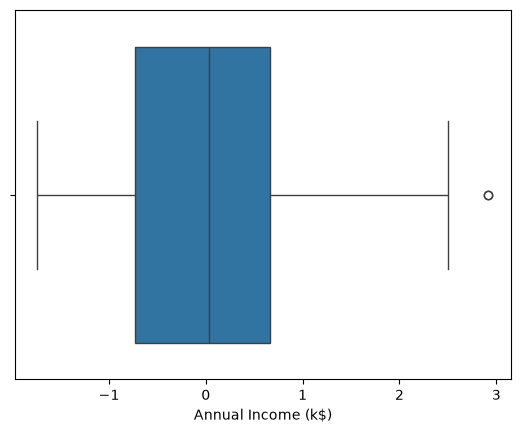

In [14]:
sns.boxplot(data , x ='Annual Income (k$)')

In [15]:
from tqdm import tqdm
wcss = []
for k in tqdm(range(1,11)):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(data)
    wcss.append(model.inertia_)

100%|██████████████████████████████████████████| 10/10 [00:00<00:00, 27.85it/s]


In [16]:
wcss

[649.2799999999999,
 438.52241155677746,
 344.6849402132781,
 254.28290726083472,
 216.7849015165104,
 181.9514362434146,
 167.8213435739793,
 150.66474655492777,
 138.8627964019021,
 133.32664005446088]

Text(0.5, 1.0, 'Elbow Method')

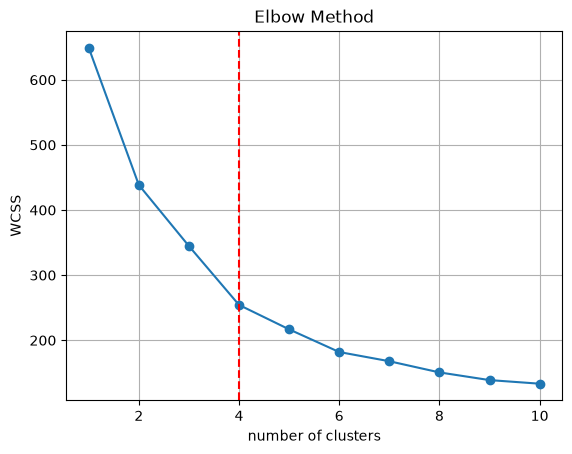

In [17]:
plt.plot(range(1,11), wcss, marker='o')
plt.axvline(4 , linestyle='--' , color='red')
plt.grid(True)
# plt.xlabel('Elbow method')
plt.xlabel('number of clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')

In [18]:
optimal_k=4

# Silhouette Score

In [19]:
sscores=[]

for k in tqdm(range(2,11)):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(data)
    score = silhouette_score(data , labels)
    sscores.append(score)

100%|████████████████████████████████████████████| 9/9 [00:00<00:00, 26.38it/s]


In [20]:
sscores

[0.30319765641607577,
 0.3150351420814524,
 0.35027020434653977,
 0.34977050035201074,
 0.356485834425401,
 0.343309990954445,
 0.330422419595931,
 0.33996050475966766,
 0.30866345259814115]

In [21]:
np.argmax(sscores)

np.int64(4)

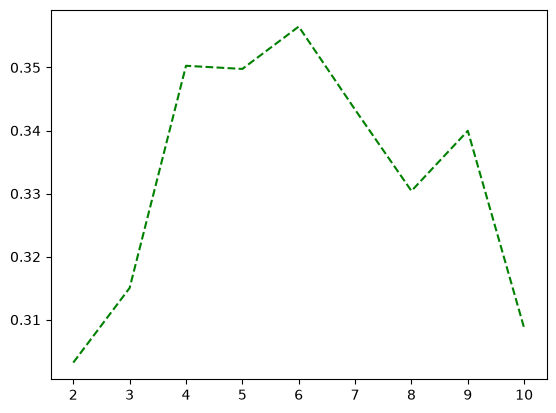

In [22]:
plt.plot(range(2,11) , sscores , linestyle='--' , color='g')
# plt.axvline(sscores[np.argmax(sscores)] , color='r')

In [23]:
optimal_k

4

In [24]:
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

clusters=kmeans.fit_predict(data)

In [25]:
data['clusters'] = clusters

In [26]:
df = data.drop('clusters' , axis=1)

In [27]:
data['clusters'].value_counts()

clusters
3    65
1    57
0    40
2    38
Name: count, dtype: int64

In [28]:
df

,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,-1.424569,-1.738999,-0.434801
1,1,-1.281035,-1.738999,1.195704
2,0,-1.352802,-1.700830,-1.715913
3,0,-1.137502,-1.700830,1.040418
4,0,-0.563369,-1.662660,-0.395980
...,...,...,...,...
195,0,-0.276302,2.268791,1.118061
196,0,0.441365,2.497807,-0.861839
197,1,-0.491602,2.497807,0.923953
198,1,-0.491602,2.917671,-1.250054


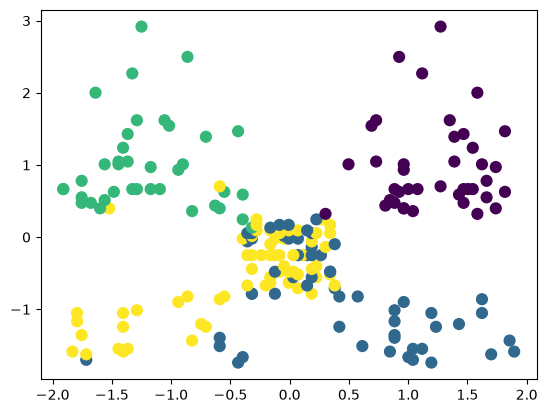

In [32]:
plt.scatter(df['Spending Score (1-100)'],df['Annual Income (k$)'], c = clusters , cmap='viridis' , s=60)

In [30]:
centers = kmeans.cluster_centers_
centers

array([[ 0.45      , -0.42880597,  0.97484722,  1.21608539],
       [ 0.40350877, -0.96249203, -0.78476346,  0.39202966],
       [ 0.5       ,  0.03720536,  0.99011499, -1.18875705],
       [ 0.43076923,  1.08616125, -0.49056525, -0.39717443]])

In [31]:
centers[:,0]

array([0.45      , 0.40350877, 0.5       , 0.43076923])

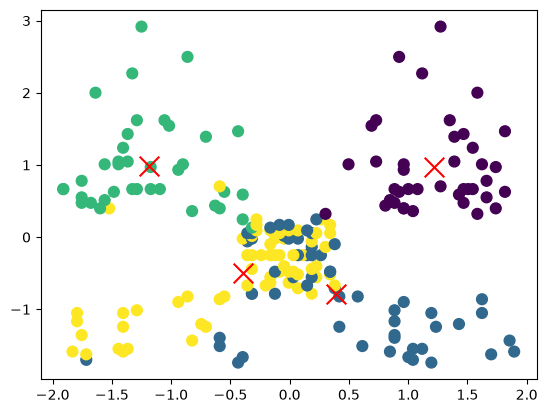

In [40]:
plt.scatter(df['Spending Score (1-100)'],df['Annual Income (k$)'], c = clusters , cmap='viridis' , s=60)
plt.scatter(centers[:,3],
           centers[:,2],
           c='r',
           s=200,
           marker='x',
           label='centroids')